# Task 2 – Tank Battle: Minimax, Alpha-Beta, Heuristic, Iterative Deepening

Notebook của Người A: phần **AI tìm kiếm đối kháng** (`src/task2_tank_battle/ai/`) và **benchmark** 4 cấu hình
(`MINIMAX`, `ALPHABETA`, `H_MINIMAX`, `H_ALPHABETA`) theo đề bài.

> **Lưu ý quan trọng về nguồn dữ liệu.** Engine luật chơi (`engine.GameRules`, `engine.MapLoader`) thuộc Người B. Notebook tự thử dùng engine của B;
> nếu engine chưa cài đặt thì dùng `StubForwardModel` (test double của Người A trong `tests/task2/doubles/`, cài đặt lại luật theo đề bài).
> Ô dưới đây in ra **mô hình nào đang được dùng**; kết quả trên stub **phải chạy lại** khi engine thật của B hoàn thành.

In [1]:
import os, sys, platform, json, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()
os.chdir(ROOT)   # paths in experiments/configs/task2.json are relative to the repo root
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "tests" / "task2" / "doubles"))

import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

from task2_tank_battle.contracts.types import Action
from task2_tank_battle.ai import (TurnSequencedGame, TerminalOnlyEvaluator, HeuristicEvaluator, MinimaxSearch,
                                  AlphaBetaSearch, IterativeDeepeningDriver, SearchAgent, MoveOrderer)
from task2_tank_battle.benchmark import SearchBenchmarkRunner, CONFIGS

MAP1 = ROOT / "src/task2_tank_battle/maps/scenarios/s1_duel_5x5.map"
try:
    from task2_tank_battle.engine import GameRules, MapLoader
    model, load_map = GameRules(), MapLoader().load
    load_map(MAP1)                       # raises NotImplementedError while B has not implemented it
    MODEL_NAME = "engine (Người B)"
except NotImplementedError:
    from stub_forward_model import StubForwardModel, load_map
    model = StubForwardModel()
    MODEL_NAME = "StubForwardModel (test double của Người A) - engine của B chưa cài đặt"
print("Python", platform.python_version(), "|", platform.platform())
print("Mô hình luật đang dùng:", MODEL_NAME)

Python 3.12.3 | Linux-6.18.44-fc-v185-x86_64-with-glibc2.39
Mô hình luật đang dùng: StubForwardModel (test double của Người A) - engine của B chưa cài đặt


## 1. Bài toán tìm kiếm đối kháng

* **Trạng thái** `GameState`: kích thước bản đồ, chu kỳ hiện tại, hai xe tăng (vị trí, hướng, HP), hai căn cứ, tường, đạn (bất biến, hashable).
* **Hành động**: `MOVE_UP/DOWN/LEFT/RIGHT`, `FIRE`, `STAY` (từ `model.legal_actions`).
* **Chuyển trạng thái**: `model.step(state, {0: a0, 1: a1})` – một *chu kỳ* gồm hai hành động **đồng thời**.
* **Kết thúc**: một xe/căn cứ bị phá hoặc hết số chu kỳ (`model.outcome`: thắng P0, thắng P1, hoà).
* **Zero-sum**: giá trị của P0 = −giá trị của P1.

**Cây tìm kiếm** (`TurnSequencedGame`): Minimax cần các lượt xen kẽ, nên mỗi chu kỳ đồng thời được tách thành hai *ply*:
MAX chọn hành động, rồi MIN chọn hành động (MIN biết hành động của MAX), sau đó mới gọi `step`. Đây là cận **thận trọng** cho MAX
(đối thủ được phép phản ứng). Độ sâu đo bằng ply; `depth = 2k` nghĩa là xem trước `k` chu kỳ; độ sâu lẻ được làm tròn lên.

In [2]:
start = load_map(MAP1)
game = TurnSequencedGame(model, max_player=0)
print("Hành động hợp lệ của P0:", [a.value for a in game.legal_actions(start, 0)])
nxt = game.advance_cycle(start, Action.FIRE, Action.STAY)
print("Sau (P0 FIRE, P1 STAY): HP xe tăng P1 =", nxt.tanks[1].hp, "| chu kỳ =", nxt.cycle)

Hành động hợp lệ của P0: ['MOVE_UP', 'MOVE_DOWN', 'MOVE_LEFT', 'MOVE_RIGHT', 'FIRE', 'STAY']
Sau (P0 FIRE, P1 STAY): HP xe tăng P1 = 5 | chu kỳ = 1


## 2. Thuật toán

**Minimax** (`MinimaxSearch`): duyệt toàn bộ cây đến độ sâu giới hạn; MAX lấy giá trị lớn nhất, MIN lấy nhỏ nhất. Nút lá = trạng thái kết thúc hoặc hết độ sâu → `evaluator.evaluate`.
Thắng sớm/thua muộn được ưu tiên bằng cách cộng/trừ số chu kỳ còn lại vào giá trị trạng thái kết thúc.

**Alpha-Beta** (`AlphaBetaSearch`): cùng giá trị gốc với Minimax nhưng cắt các nhánh không thể ảnh hưởng kết quả (`β ≤ α`). Ghi lại số nút duyệt, số lần cắt (`cutoffs`) và số nhánh anh em bị bỏ qua (`nodes_pruned`).
Tuỳ chọn: `MoveOrderer` (FIRE trúng địch trước, nước đi tiến về căn cứ địch, STAY sau cùng) và `TranspositionTable` (chỉ lưu giá trị *chính xác*).

**Hàm đánh giá**
* `TerminalOnlyEvaluator`: ±10 000 khi thắng/thua, 0 khi hoà hoặc chưa kết thúc (cấu hình `MINIMAX`, `ALPHABETA`).
* `HeuristicEvaluator` (cấu hình `H_*`): với mỗi đặc trưng lấy *(của mình) − (của địch)* nên luôn đối xứng `eval(s,0) = −eval(s,1)`:
  HP xe tăng (×100), HP căn cứ (×60), mức độ áp sát căn cứ địch (×3), chiến thuật (×15): +2 nếu đang ngắm đúng xe/căn cứ địch với đường bắn thông, +1 nếu thẳng hàng với xe địch,
  −2/−1 cho mỗi viên đạn địch đang bay thẳng tới xe/căn cứ của mình. Chỉ dùng thông tin có trong `GameState`. Giá trị heuristic luôn nhỏ hơn nhiều so với ±10 000 của trạng thái kết thúc.

**Iterative Deepening** (`IterativeDeepeningDriver`): tìm với độ sâu 2, 4, 6, … bằng Alpha-Beta; giữ hành động của độ sâu **hoàn tất cuối cùng**, bỏ kết quả dở dang khi hết giờ
(`SearchTimeout`), dừng sớm khi đã thấy thắng/thua chắc chắn; nếu chưa kịp xong độ sâu 2 thì trả về nước đi có thứ hạng tốt nhất theo `MoveOrderer`.
`SearchAgent` bọc tất cả lại theo `TankAgent`, **không bao giờ ném exception** và luôn trả về hành động hợp lệ (fallback khi lỗi/timeout).

## 3. Ví dụ chạy thực tế

In [3]:
pos = load_map(ROOT / "src/task2_tank_battle/maps/scenarios/s2_obstacles_9x9.map")
rows = []
for name, spec in CONFIGS.items():
    ev = HeuristicEvaluator(model) if spec["heuristic"] else TerminalOnlyEvaluator(model)
    cls = AlphaBetaSearch if spec["algorithm"] == "alphabeta" else MinimaxSearch
    r = cls(model, ev).search(pos, 0, 4)
    rows.append({"config": name, "best_action": r.best_action.value, "value": r.value, "nodes": r.stats.nodes_expanded,
                 "pruned": r.stats.nodes_pruned, "cutoffs": r.stats.cutoffs, "ms": r.stats.elapsed_s * 1e3})
demo = pd.DataFrame(rows); demo.round(3)

,config,best_action,value,nodes,pruned,cutoffs,ms
0,MINIMAX,MOVE_UP,0.0,1555,0,0,22.861
1,ALPHABETA,MOVE_UP,0.0,130,225,45,1.448
2,H_MINIMAX,MOVE_UP,0.0,1555,0,0,31.064
3,H_ALPHABETA,MOVE_UP,0.0,135,220,45,3.348


Alpha-Beta cho **cùng giá trị gốc** với Minimax (cùng evaluator, cùng độ sâu) nhưng duyệt ít nút hơn. Kiểm tra trên nhiều vị trí lấy từ ván chơi ngẫu nhiên:

In [4]:
from task2_tank_battle.benchmark import sample_positions
checks = []
for scen in ("s1_duel_5x5", "s2_obstacles_9x9", "s3_arena_13x13"):
    s0 = load_map(ROOT / f"src/task2_tank_battle/maps/scenarios/{scen}.map")
    for p in sample_positions(model, s0, 6, seed=7):
        for ev in (TerminalOnlyEvaluator(model), HeuristicEvaluator(model)):
            a = MinimaxSearch(model, ev).search(p, 0, 4); b = AlphaBetaSearch(model, ev).search(p, 0, 4)
            checks.append(a.value == b.value and a.best_action == b.best_action)
print(f"{sum(checks)}/{len(checks)} trường hợp: cùng giá trị gốc và cùng hành động")

36/36 trường hợp: cùng giá trị gốc và cùng hành động


In [5]:
# Iterative deepening với ngân sách thời gian
drv = IterativeDeepeningDriver(model, HeuristicEvaluator(model), max_depth=20)
for budget in (0.05, 0.3, 1.0):
    t0 = time.perf_counter(); res = drv.search(pos, 0, budget)
    print(f"ngân sách {budget:4.2f}s -> dùng {time.perf_counter()-t0:5.3f}s, hoàn tất độ sâu {res.depth_completed_plies:2d} ply, "
          f"hành động {res.best_action.value:10s} (hết giờ: {res.timed_out})")

ngân sách 0.05s -> dùng 0.049s, hoàn tất độ sâu  6 ply, hành động MOVE_UP    (hết giờ: True)


ngân sách 0.30s -> dùng 0.272s, hoàn tất độ sâu  8 ply, hành động MOVE_UP    (hết giờ: True)


ngân sách 1.00s -> dùng 0.902s, hoàn tất độ sâu 10 ply, hành động MOVE_UP    (hết giờ: True)


## 4. Benchmark 4 cấu hình

Cấu hình: `experiments/configs/task2.json` – 3 bản đồ kịch bản, độ sâu 2/4/6 ply, 4 vị trí mỗi bản đồ (cùng vị trí cho mọi cấu hình, trích từ ván chơi ngẫu nhiên có seed),
giới hạn 10 s mỗi lần tìm; sau đó mỗi cấu hình đấu 10 ván với đối thủ ngẫu nhiên trên mỗi bản đồ (đổi bên xen kẽ), độ sâu cố định 4 ply, tối đa 100 chu kỳ/ván
(hết giới hạn → hoà). Không đo bộ nhớ: Minimax/Alpha-Beta duyệt theo chiều sâu nên bộ nhớ chỉ tỉ lệ với độ sâu (không đáng kể).

In [6]:
CONFIG = ROOT / "experiments/configs/task2.json"
OUT = ROOT / "experiments/results"
t0 = time.perf_counter()
SearchBenchmarkRunner(model, load_map).run(CONFIG, OUT)
print(f"Benchmark xong sau {time.perf_counter()-t0:.0f}s")
meta = json.loads((OUT / "task2_benchmark_meta.json").read_text())
print({k: meta[k] for k in ("created_utc", "python", "platform", "processor", "forward_model")})
srch = pd.read_csv(OUT / "task2_search_summary.csv"); mt = pd.read_csv(OUT / "task2_matches_summary.csv")

Benchmark xong sau 193s
{'created_utc': '2026-11-02T08:14:41+00:00', 'python': '3.12.3', 'platform': 'Linux-6.18.44-fc-v185-x86_64-with-glibc2.39', 'processor': 'x86_64', 'forward_model': 'stub_forward_model.StubForwardModel'}


### 4.1 Chi phí tìm kiếm theo độ sâu (trung bình trên các vị trí)

In [7]:
order = list(CONFIGS)
for col, label in [("mean_nodes", "Số nút được duyệt"), ("mean_time_s", "Thời gian trung bình (s)"), ("mean_pruned", "Số nhánh bị cắt")]:
    print(label); print(srch.pivot_table(index=["scenario", "depth_ply"], columns="config", values=col)[order].round(4).to_string()); print()
print("Số lần hết giờ (timeouts):", int(srch.timeouts.sum()))

Số nút được duyệt
config                       MINIMAX  ALPHABETA  H_MINIMAX  H_ALPHABETA
scenario         depth_ply                                             
s1_duel_5x5      2             43.00      18.00      43.00        29.75
                 4           1555.00     130.00    1555.00       540.25
                 6          55876.00     811.25   55876.00      5697.00
s2_obstacles_9x9 2             43.00      18.00      43.00        23.25
                 4           1533.50     129.50    1533.50       278.50
                 6          54631.75     805.75   54631.75      2215.75
s3_arena_13x13   2             38.00      16.75      38.00        21.50
                 4           1301.00     117.75    1301.00       183.50
                 6          45618.50     725.50   45618.50      1815.75

Thời gian trung bình (s)
config                      MINIMAX  ALPHABETA  H_MINIMAX  H_ALPHABETA
scenario         depth_ply                                            
s1_duel_5x5      2    

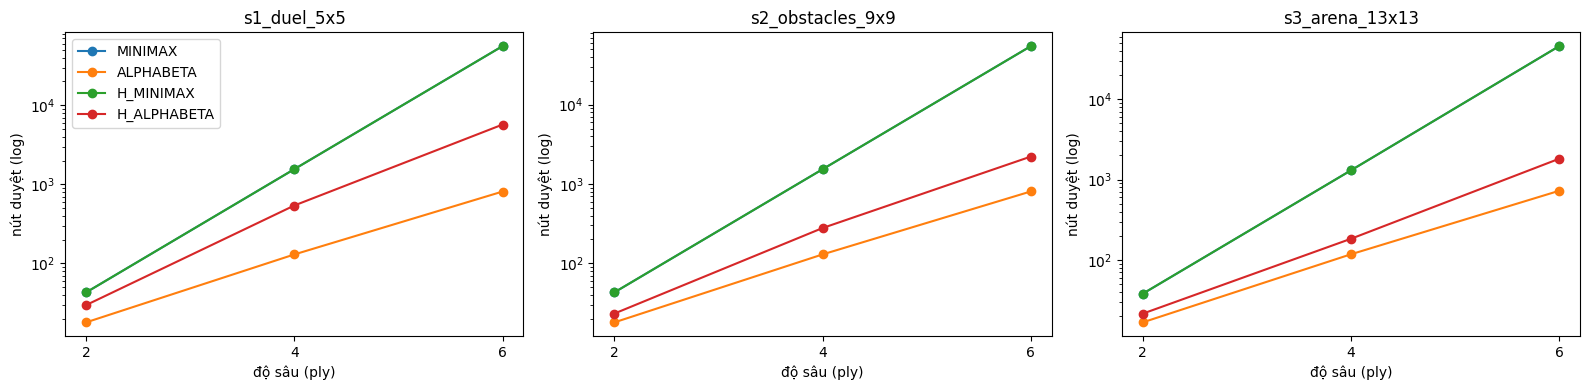

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for a, (scen, g) in zip(ax, srch.groupby("scenario")):
    for cfg in order:
        h = g[g.config == cfg]; a.plot(h.depth_ply, h.mean_nodes, "o-", label=cfg)
    a.set_yscale("log"); a.set_title(scen); a.set_xlabel("độ sâu (ply)"); a.set_ylabel("nút duyệt (log)"); a.set_xticks([2, 4, 6])
ax[0].legend(); plt.tight_layout(); plt.show()

In [9]:
d6 = srch[srch.depth_ply == 6].pivot_table(index="scenario", columns="config", values="mean_nodes")
ratio = pd.DataFrame({"ALPHABETA / MINIMAX": d6.ALPHABETA / d6.MINIMAX, "H_ALPHABETA / H_MINIMAX": d6.H_ALPHABETA / d6.H_MINIMAX})
print("Tỉ lệ số nút duyệt ở độ sâu 6 (nhỏ hơn = cắt tỉa hiệu quả hơn):"); (ratio * 100).round(2).astype(str) + " %"

Tỉ lệ số nút duyệt ở độ sâu 6 (nhỏ hơn = cắt tỉa hiệu quả hơn):


,ALPHABETA / MINIMAX,H_ALPHABETA / H_MINIMAX
scenario,,
s1_duel_5x5,1.45 %,10.2 %
s2_obstacles_9x9,1.47 %,4.06 %
s3_arena_13x13,1.59 %,3.98 %


### 4.2 Kết quả ván đấu với đối thủ ngẫu nhiên

In [10]:
mt[["scenario", "config", "games", "wins", "draws", "losses", "win_rate", "mean_cycles", "mean_ms_per_move", "mean_nodes_per_move"]].round(3)

,scenario,config,games,wins,draws,losses,win_rate,mean_cycles,mean_ms_per_move,mean_nodes_per_move
0,s1_duel_5x5,MINIMAX,10,0,10,0,0.0,100.0,16.654,1529.542
1,s1_duel_5x5,ALPHABETA,10,0,10,0,0.0,100.0,1.090,128.750
2,s1_duel_5x5,H_MINIMAX,10,10,0,0,1.0,9.4,23.859,1529.851
3,s1_duel_5x5,H_ALPHABETA,10,10,0,0,1.0,9.4,6.096,388.670
4,s2_obstacles_9x9,MINIMAX,10,0,10,0,0.0,100.0,21.988,1521.880
5,s2_obstacles_9x9,ALPHABETA,10,0,10,0,0.0,100.0,1.605,128.347
6,s2_obstacles_9x9,H_MINIMAX,10,4,6,0,0.4,81.7,31.428,1518.458
7,s2_obstacles_9x9,H_ALPHABETA,10,4,6,0,0.4,81.7,4.993,272.802
8,s3_arena_13x13,MINIMAX,10,0,10,0,0.0,100.0,37.906,1509.394
9,s3_arena_13x13,ALPHABETA,10,0,10,0,0.0,100.0,2.452,127.973


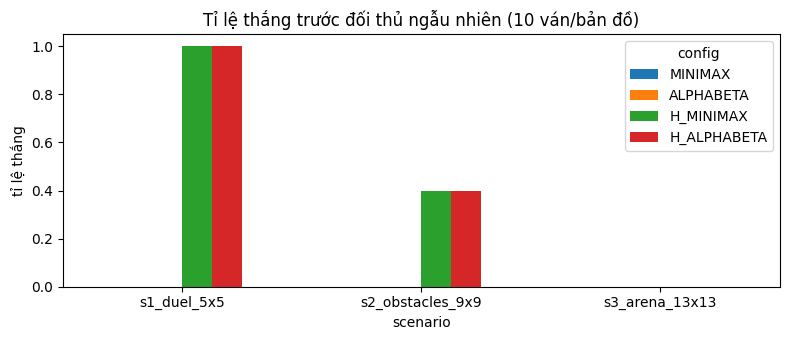

In [11]:
mt.pivot_table(index="scenario", columns="config", values="win_rate")[order].plot.bar(figsize=(8, 3.5), rot=0)
plt.ylabel("tỉ lệ thắng"); plt.title("Tỉ lệ thắng trước đối thủ ngẫu nhiên (10 ván/bản đồ)"); plt.tight_layout(); plt.show()

## 5. Nhận xét

*(Dựa trên bảng/biểu đồ vừa sinh ra; mô hình luật được dùng nêu ở đầu notebook.)*

* **Alpha-Beta ≡ Minimax về giá trị**: ở mọi vị trí đã kiểm tra, hai thuật toán cho cùng giá trị gốc và cùng hành động; trong benchmark, `H_MINIMAX` và `H_ALPHABETA` (và cặp không heuristic) có **cùng số ván thắng/hoà**, đúng như kỳ vọng.
* **Cắt tỉa hiệu quả**: Minimax duyệt khoảng 40–55 nghìn nút ở độ sâu 6 trong khi Alpha-Beta chỉ cần vài trăm đến vài nghìn (xem bảng tỉ lệ); chênh lệch tăng theo độ sâu, nên thời gian ở độ sâu 6 giảm từ ~1–2 s xuống khoảng 10–130 ms (tuỳ cấu hình và bản đồ).
* **Evaluator chỉ có thắng/thua (`MINIMAX`, `ALPHABETA`) rất yếu**: ở độ sâu 4 ply hầu hết trạng thái chưa kết thúc đều có giá trị 0 nên thuật toán không có định hướng; các cấu hình này **không thắng ván nào** (toàn hoà ở giới hạn 100 chu kỳ).
  Alpha-Beta lúc này còn cắt tỉa rất mạnh do có rất nhiều giá trị bằng nhau – số nút thấp hơn heuristic nhưng đó là vì thông tin ít, không phải vì thuật toán tốt hơn.
* **Heuristic tạo khác biệt về chất lượng**: `H_MINIMAX`/`H_ALPHABETA` thắng cả 10 ván ở bản đồ 5×5 (trung bình ~9 chu kỳ/ván) và 4/10 ván ở bản đồ 9×9 nhưng 0/10 ở bản đồ 13×13 trong 100 chu kỳ:
  với tầm nhìn 2 chu kỳ, trên bản đồ lớn tầm xa chưa đủ để nhìn thấy thắng lợi, và heuristic hiện tại chưa có thành phần dẫn đường quanh vật cản (dùng khoảng cách Manhattan).
  Đây là hướng cải thiện (ví dụ khoảng cách BFS có tính tường).
* **Hạn chế quan trọng**: (1) toàn bộ số liệu chạy trên `StubForwardModel` nếu mục đầu ghi như vậy – cần chạy lại bằng engine của Người B; (2) đối thủ chỉ là bot ngẫu nhiên, chưa phải đối thủ mạnh;
  (3) số ván mỗi ô là 10 nên tỉ lệ thắng có sai số lớn; (4) giả định toạ độ `(hàng, cột)` với UP làm giảm hàng (`ai/geometry.py`) – cần B xác nhận.